# Raw data only vs. multiple views

* **(A)** a true drift — the season + gradient detector fires inside the
  window that covers it;
* **(B)** a false alarm of the raw-only detector — on the very same window the
  gradient and seasonal views see no change, so the majority vote stays quiet.


In [13]:
from pathlib import Path as _Path
import os as _os

for _candidate in (_Path.cwd(), *_Path.cwd().parents):
    if (_candidate / "KALEIDO_multi_instance.py").is_file() and (_candidate / "stable_windows.csv").is_file():
        _code_dir = _candidate
        break
    _nested = _candidate / "results_all_in_one_code"
    if (_nested / "KALEIDO_multi_instance.py").is_file() and (_nested / "stable_windows.csv").is_file():
        _code_dir = _nested
        break
else:
    raise FileNotFoundError("Could not locate results_all_in_one_code; start this notebook inside the repository")

_os.chdir(_code_dir)
(_code_dir / "figures").mkdir(exist_ok=True)
(_code_dir / "example_runs").mkdir(exist_ok=True)
import os, sys, time, pickle
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, ConnectionPatch
from scipy.stats import ks_2samp, gaussian_kde
from tqdm.auto import tqdm
from IPython.display import display
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator



In [14]:
# ---- data ------------------------------------------------------------------
CODE_DIR = 'results_all_in_one_code'
DATA_DIR = f'{CODE_DIR}/datasets/synthetic_random_datasets'
STREAMS_CSV = f'../{DATA_DIR}/time_series_random_noisy_100.csv'
LABELS_CSV = f'../{DATA_DIR}/drift_labels_random_noisy_100.csv'
STABLE_WINDOWS_CSV = f'{CODE_DIR}/stable_windows.csv'   # optional
TIMESERIES = 'random_noisy'                            # key in stable_windows.csv
STREAM_ID = 0

# ---- detector (same as KALEIDO_multi_instance.py) -----------------
DELTA, METHOD, ALTERNATIVE, STAT_VALUE, DIST_CHANGE_METHOD = 0.05, 'asymp', 'two-sided', 0.1, 'ks'
DEFAULT_WINDOWS = (680, 1360)          # (min_eval_window, eval_no_shrink_window)
RAW_FEATURES = ['normal_data']
MULTI_FEATURES = ['season', 'gradient']

# ---- case selection ----------------------------------------------------------
# None = pick automatically (see the "choose the two cases" cell); otherwise give the
# window_end (sample index) of the alarm to show, e.g. CASE_A = 4312, CASE_B = 2000
CASE_A = None     # true drift caught by season + gradient
CASE_B = None     # raw-only false alarm, ignored by season + gradient

OUT_PNG = 'figures/drift_case_studies.png'
CACHE = 'example_runs/drift_case_runs.pkl'

for p in (CODE_DIR, '.'):
    if p not in sys.path:
        sys.path.insert(0, p)
from KALEIDO_TRANSFORMATIONS import KALEIDO


def find_file(path):
    if os.path.exists(path):
        return path
    if os.path.exists(os.path.basename(path)):
        return os.path.basename(path)
    raise FileNotFoundError(path)


def load_variable_column_csv(file_path, delimiter=','):
    with open(file_path) as f:
        n_cols = max(len(l.split(delimiter)) for l in f) + 1
    return pd.read_csv(file_path, header=None, delimiter=delimiter, names=range(n_cols))

## Load the stream

In [15]:
streams = load_variable_column_csv(find_file(STREAMS_CSV))
labels_all = load_variable_column_csv(find_file(LABELS_CSV))


def get_stream(stream_id):
    x = pd.Series(streams.iloc[stream_id].values).dropna().values
    lab = labels_all.iloc[stream_id].dropna().values.astype(int)
    return x, lab


data_stream, drift_labels = get_stream(STREAM_ID)

min_eval_window, eval_no_shrink_window = DEFAULT_WINDOWS
try:
    w = pd.read_csv(find_file(STABLE_WINDOWS_CSV)).set_index('time_series')
    min_eval_window = int(w.loc[TIMESERIES, 'min_window_p95'])
    eval_no_shrink_window = int(w.loc[TIMESERIES, 'max_window'])
except (FileNotFoundError, KeyError):
    pass
print(f'stream {STREAM_ID}: {len(data_stream)} samples, drifts at {drift_labels.tolist()}; '
      f'windows ({min_eval_window}, {eval_no_shrink_window})')

stream 0: 11818 samples, drifts at [3751, 8505]; windows (200, 400)


In [16]:
class RecordingKALEIDO(KALEIDO):
    """KALEIDO that keeps, for every evaluation, what each view saw and decided."""

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.log = []

    def our_algo(self, *args, **kwargs):
        w = np.asarray(self.window_I, dtype=float)
        out = super().our_algo(*args, **kwargs)
        drift, _, _, _, _, p_values, _, results = out
        self.log.append(dict(step=len(self.original_data), window_size=len(w),
                             pvals=list(p_values), stats=list(self.alternatives_stats),
                             votes=list(results), drift=bool(drift)))
        return out


def boyer_moore_majority_vote(nums):
    candidate, count = None, 0
    for n in nums:
        if count == 0:
            candidate = n
        count += 1 if n == candidate else -1
    return candidate if sum(n == candidate for n in nums) > len(nums) // 2 else None


def run_detector(data_stream, alternatives, min_eval_window, eval_no_shrink_window,
                 use_ttest=False, verbose=True):
    detector = RecordingKALEIDO(delta=DELTA, method=METHOD, alternative=ALTERNATIVE,
                                 eval_noshrink_window=eval_no_shrink_window,
                                 min_eval_window=min_eval_window,
                                 dist_change_method=DIST_CHANGE_METHOD, stat_value=STAT_VALUE,
                                 alternatives=alternatives, use_ttest=use_ttest)
    transformation = lambda d: np.array(d)
    name = 'normal_data'
    history, by_middle, vote_results = defaultdict(list), defaultdict(dict), []
    vote_value = min_eval_window / 2 - 1

    def record(nm, t):
        history[nm].append(t)
        by_middle[nm][t[1]] = t

    it = enumerate(data_stream, start=1)
    if verbose:
        it = tqdm(it, total=len(data_stream), desc='+'.join(alternatives), leave=False)
    for i, val in it:
        drift = detector.update(val, transformation, None, eval=not (i < vote_value))
        if drift is None:
            continue
        window_size = detector.get_window_size()[-1]
        middle = int(np.ceil(i - window_size / 2))
        prev = history[name][-1] if history[name] else None
        if prev is not None and i >= min_eval_window:
            for step in range(prev[1] + 1, middle):
                record(name, (prev[0], step, prev[2], prev[3], False))
        record(name, (i, middle, drift, window_size, True))
        while True:
            votes = [by_middle[nm][vote_value][2] for nm in history if vote_value in by_middle[nm]]
            if len(votes) != len(history):
                break
            vote_results.append((vote_value, boyer_moore_majority_vote(votes)))
            vote_value += 1
            if vote_results[-1][1] is True:
                vote_value += max(by_middle[nm][vote_value - 1][3] for nm in history)

    alarms = []
    for mid, is_drift in vote_results:
        if is_drift:
            t = by_middle[name][mid]
            alarms.append(dict(middle=int(mid), window_start=int(t[0] - t[3]),
                               window_end=int(t[0]), window_size=int(t[3])))
    return dict(alarms=alarms, log=detector.log, views=list(alternatives))


def covers_drift(a, labels):
    return any(a['window_start'] <= l < a['window_end'] for l in labels)


def score(alarms, labels):
    tp = [a for a in alarms if covers_drift(a, labels)]
    found = {l for l in labels for a in tp if a['window_start'] <= l < a['window_end']}
    precision = len(tp) / len(alarms) if alarms else 0.0
    recall = len(found) / len(labels) if len(labels) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(alarms=len(alarms), TP=len(tp), FP=len(alarms) - len(tp), FN=len(labels) - len(found),
                precision=round(precision, 3), recall=round(recall, 3), f1=round(f1, 3))


def run_both(data_stream, labels, key):
    """Run raw-only and season+gradient on one stream; cached on disk by `key`."""
    cache = {}
    if os.path.exists(CACHE):
        with open(CACHE, 'rb') as f:
            cache = pickle.load(f)
    if key not in cache:
        res = {}
        for tag, feats in [('raw', RAW_FEATURES), ('multi', MULTI_FEATURES)]:
            t0 = time.time()
            res[tag] = run_detector(data_stream, feats, min_eval_window, eval_no_shrink_window)
            print(f'  {tag:5s}: {len(res[tag]["alarms"])} alarms in {time.time()-t0:.0f}s')
        cache[key] = res
        with open(CACHE, 'wb') as f:
            pickle.dump(cache, f)
    return cache[key]

In [17]:
_probe = KALEIDO(alternatives=['normal_data', 'gradient', 'season'])
VIEW_FUNCS = {'raw': _probe.use_normal_data, 'gradient': np.gradient, 'season': _probe.extract_season}


def view_tests(window):
    mid = len(window) // 2
    w0, w1 = np.asarray(window[:mid], float), np.asarray(window[mid:], float)
    out = {}
    for name, f in VIEW_FUNCS.items():
        a0, a1 = np.asarray(f(w0), float), np.asarray(f(w1), float)
        d, p = ks_2samp(a0, a1, method=METHOD, alternative=ALTERNATIVE)
        out[name] = dict(w0=a0, w1=a1, D=d, p=p, vote=bool(p < DELTA and d > STAT_VALUE))
    return out

## Run the detectors on the chosen stream

To look for a stream with clearer cases, set `SCAN = range(0, 10)` (each
stream takes a few minutes for the two runs) and read the table it prints:
a good stream has `multi_TP > 0` and `clean_FP > 0` (raw false alarms on whose
window both other views say "no drift" and no season+gradient alarm is nearby).

In [18]:
SCAN = None     # e.g. range(0, 10)


def candidate_cases(res, data, labels):
    """True drifts caught by season+gradient, and raw false alarms the views reject."""
    tps = [a for a in res['multi']['alarms'] if covers_drift(a, labels)]
    multi_mid = np.array([a['middle'] for a in res['multi']['alarms']] or [-1e9])
    clean_fps = []
    for a in res['raw']['alarms']:
        if covers_drift(a, labels):
            continue
        t = view_tests(data[a['window_start']:a['window_end']])
        near_multi = np.abs(multi_mid - a['middle']).min() < a['window_size']
        if t['raw']['vote'] and not t['gradient']['vote'] and not t['season']['vote'] and not near_multi:
            clean_fps.append((a, t))
    return tps, clean_fps


if SCAN is not None:
    rows = []
    for sid in SCAN:
        x, lab = get_stream(sid)
        print(f'stream {sid} ({len(x)} samples)')
        res = run_both(x, lab, f'{TIMESERIES}_{sid}_{min_eval_window}_{eval_no_shrink_window}')
        tps, fps = candidate_cases(res, x, lab)
        rows.append(dict(stream=sid, **{f'raw_{k}': v for k, v in score(res['raw']['alarms'], lab).items()},
                         **{f'multi_{k}': v for k, v in score(res['multi']['alarms'], lab).items()},
                         clean_FP=len(fps)))
    display(pd.DataFrame(rows))

results = run_both(data_stream, drift_labels, f'{TIMESERIES}_{STREAM_ID}_{min_eval_window}_{eval_no_shrink_window}')
print('raw  ', score(results['raw']['alarms'], drift_labels))
print('multi', score(results['multi']['alarms'], drift_labels))

raw   {'alarms': 13, 'TP': 2, 'FP': 11, 'FN': 0, 'precision': 0.154, 'recall': 1.0, 'f1': 0.267}
multi {'alarms': 2, 'TP': 2, 'FP': 0, 'FN': 0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0}


## Choose the two cases

In [19]:
tps, clean_fps = candidate_cases(results, data_stream, drift_labels)
print(f'{len(tps)} true drifts caught by season+gradient, {len(clean_fps)} clean raw-only false alarms')

if CASE_A is None:
    # the true-drift alarm whose window gives the strongest season/gradient evidence
    case_a = max(tps, key=lambda a: max(view_tests(data_stream[a['window_start']:a['window_end']])[v]['D']
                                        for v in ('gradient', 'season')))
else:
    case_a = next(a for a in results['multi']['alarms'] if a['window_end'] == CASE_A)
if CASE_B is None:
    # the false alarm where the raw view is most confident while the other views are not
    case_b, _ = max(clean_fps, key=lambda at: at[1]['raw']['D'] - max(at[1]['gradient']['D'], at[1]['season']['D']))
else:
    case_b = next(a for a in results['raw']['alarms'] if a['window_end'] == CASE_B)

tests_a = view_tests(data_stream[case_a['window_start']:case_a['window_end']])
tests_b = view_tests(data_stream[case_b['window_start']:case_b['window_end']])
for name, a, t in (('A (true drift)', case_a, tests_a), ('B (raw false alarm)', case_b, tests_b)):
    print(name, f"window [{a['window_start']}, {a['window_end']})",
          {v: f"D={t[v]['D']:.2f} p={t[v]['p']:.1e} vote={int(t[v]['vote'])}" for v in t})

2 true drifts caught by season+gradient, 11 clean raw-only false alarms
A (true drift) window [8324, 8546) {'raw': 'D=0.41 p=7.9e-09 vote=1', 'gradient': 'D=0.18 p=4.6e-02 vote=1', 'season': 'D=0.25 p=1.3e-03 vote=1'}
B (raw false alarm) window [11111, 11463) {'raw': 'D=0.15 p=3.9e-02 vote=1', 'gradient': 'D=0.05 p=9.9e-01 vote=0', 'season': 'D=0.06 p=9.2e-01 vote=0'}


## The figure

saved drift_case_studies.pdf


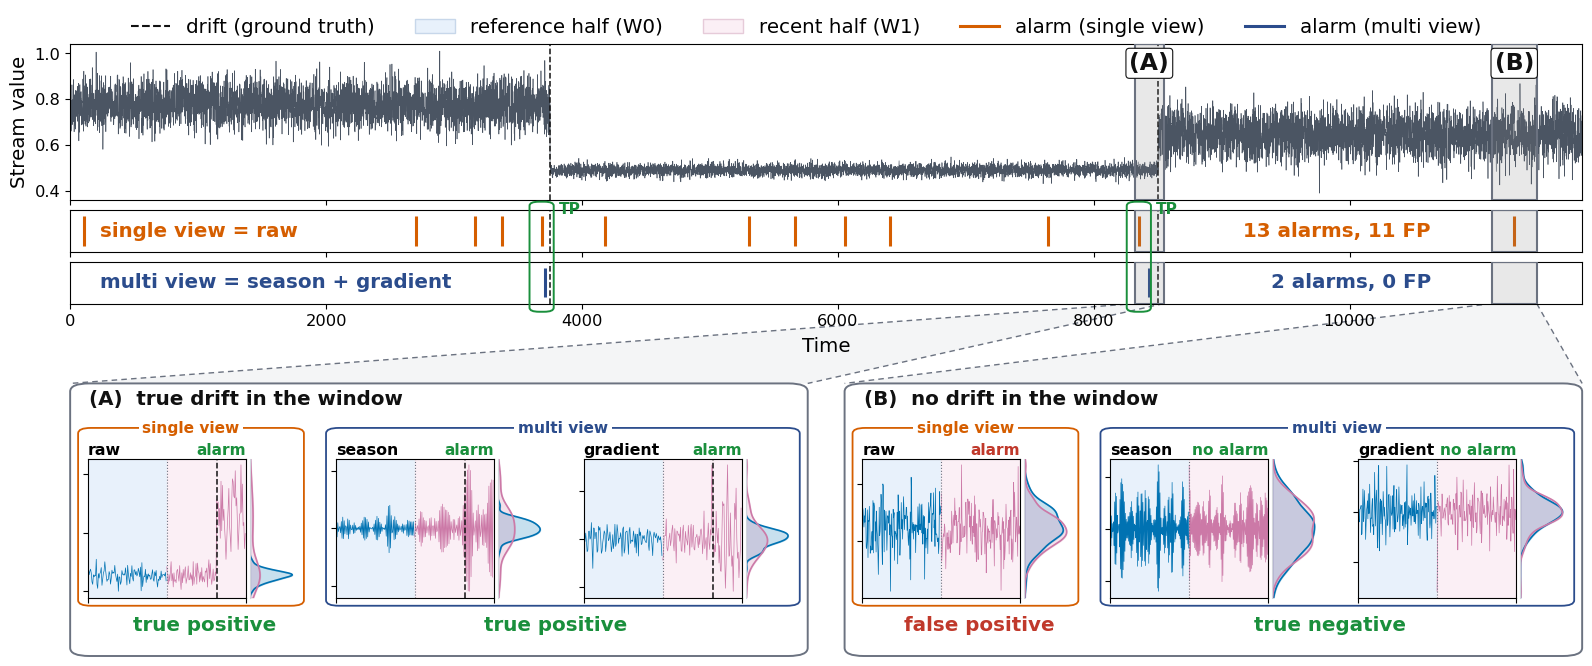

In [28]:
RAW_C, MULTI_C = '#d55e00', '#2b4c8c'                     # detector identity: raw = orange, multi-view = navy
OK_C, BAD_C = '#1a8f3c', '#c0392b'                        # verdicts: correct = green, wrong = red
GREY = '#6b7280'
SERIES_C = '#4b5563'                                      # neutral dark slate for the data
REF_C, REC_C = '#0072b2', '#cc79a7'                       # reference / recent halves (Okabe-Ito blue / purple)
REF_BG, REC_BG = '#e8f1fb', '#fbeff5'                     # lighter than before: less weight behind the lines
DRIFT_C = '#111111'
CASE_C = '#6b7280'                                        # A / B window outlines, box borders, projection lines
CASE_FILL = (0.5, 0.5, 0.5, 0.18)                         # translucent grey fill of the A / B windows on the stream

def plot_case_studies(case_a, tests_a, case_b, tests_b,
                      save=('figures/drift_case_studies.pdf', 'figures/drift_case_studies.png'),
                      figsize=(16, 6.8), dpi=180,
                      fontsize=11,                 # axis labels, legend, view names, decision text
                      title_fontsize=None,         # case / full-stream titles   (default fontsize+2)
                      tick_fontsize=None,          # tick numbers                 (default fontsize-2)
                      small_fontsize=None,         # D / p labels                 (default fontsize-2.5)
                      font_scale=1.0,              # multiplies every text size; nothing else changes
                      text_color='black', bold_family='DejaVu Sans',
                      show_decisions=True,         # one plain line per case: raw verdict + majority vote
                      marginal_width=0.28,         # width of the marginal densities relative to the sequence panel
                      box_inner=(0.025, 0.025, 0.42, 0.02),  # gutters inside a box: left, right (fraction of its width),
                                                              #                       top, bottom (fraction of its height)
                      box_fc=('white', 'white'),              # box fill for case A / case B
                      case_titles=True,            # '(A) ...' titles inside the boxes
                      connect=True,                # projection lines from the A / B windows on the stream to the boxes
                      connect_alpha=0.07,          # fill of the projection wedge (0 = lines only)
                      group_pad=(0.006, 0.012, 0.045),   # frame margins around raw / season+gradient: x, bottom, top (fig. fraction)
                      mark_tp=True,                # green bracket + 'TP' across the strips at each caught drift
                      title_a='true drift in the window',
                      title_b='no drift in the window'):
    """Full stream on top, the two case studies below, each in a box. A case is the three views side by
    side (the two halves with their distributions as a marginal on the right edge) plus one decision line;
    the raw view and the season + gradient views are each framed in their detector's colour.
    Text uses DejaVu Sans; bold text uses `bold_family`. Fonts are set here, so call it after any
    seaborn theme change."""
    title_fontsize = title_fontsize or fontsize + 2
    tick_fontsize = tick_fontsize or fontsize - 2
    small_fontsize = small_fontsize or fontsize - 2.5
    fontsize, title_fontsize, tick_fontsize, small_fontsize = (
        v * font_scale for v in (fontsize, title_fontsize, tick_fontsize, small_fontsize))
    mpl.rcParams.update({
        'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
        'mathtext.fontset': 'dejavusans', 'axes.formatter.use_mathtext': False,
        'pdf.fonttype': 42, 'ps.fonttype': 42,
        'font.size': fontsize, 'axes.labelsize': fontsize, 'axes.titlesize': fontsize,
        'xtick.labelsize': tick_fontsize, 'ytick.labelsize': tick_fontsize, 'legend.fontsize': fontsize,
        'text.color': text_color, 'axes.labelcolor': text_color, 'axes.titlecolor': text_color,
        'xtick.color': text_color, 'ytick.color': text_color,
    })
    arrow = r'$\rightarrow$'

    def marginal(axm, w0, w1, ylim):
        """The two densities, rotated, sharing the y-axis of the sequence panel on their left."""
        ys = np.linspace(*ylim, 200)
        for arr, c in ((w0, REF_C), (w1, REC_C)):
            k = gaussian_kde(arr)(ys)
            axm.plot(k, ys, color=c, lw=1.2); axm.fill_betweenx(ys, 0, k, color=c, alpha=0.22)
        axm.set_ylim(*ylim); axm.set_xlim(0, None); axm.set_xticks([]); axm.set_yticks([])
        for sp in ('top', 'right', 'bottom'):
            axm.spines[sp].set_visible(False)
        axm.spines['left'].set_color('#d1d5db')

    def view_panel(fig, cell, t, title, s, m, e):
        """One view: the two halves on the left, their marginal densities on the right."""
        g = cell.subgridspec(1, 2, width_ratios=[1, marginal_width], wspace=0.04)
        ax, axm = fig.add_subplot(g[0]), fig.add_subplot(g[1])
        ax.axvspan(s, m, color=REF_BG, zorder=0); ax.axvspan(m, e, color=REC_BG, zorder=0)
        ax.plot(np.arange(s, m), t['w0'], color=REF_C, lw=0.5)
        ax.plot(np.arange(m, e), t['w1'], color=REC_C, lw=0.5)
        ax.axvline(m, color=GREY, lw=0.8, ls=':')
        for l in drift_labels:
            if s <= l < e:
                ax.axvline(l, color=DRIFT_C, ls='--', lw=1.1)
        ax.set_xlim(s, e); ax.set_xticks([s, e])             # window start / end
        ax.yaxis.set_major_locator(MaxNLocator(3))
        ax.set_title(title, loc='left', fontsize=fontsize-3, fontfamily=bold_family, fontweight='bold', pad=3)
        # ax.set_xlabel(f'$D$ = {t["D"]:.2f}, $p$ = {t["p"]:.1e}', fontsize=small_fontsize, color=GREY, labelpad=3)
        ax.tick_params(labelbottom=False, labelleft=False)

        marginal(axm, t['w0'], t['w1'], ax.get_ylim())
        wrong = t['vote'] and not any(s <= l < e for l in drift_labels)   # alarm with no drift in the window
        ax.set_title('alarm' if t['vote'] else 'no alarm', loc='right', fontsize=small_fontsize,
                     fontfamily=bold_family, fontweight='bold', color=BAD_C if wrong else OK_C, pad=3)
        return ax

    def draw_full_stream(ax_ts, ax_raw, ax_multi, cases):
        n = len(data_stream)
        ax_ts.plot(data_stream, color=SERIES_C, lw=0.45)
        for ax in (ax_ts, ax_raw, ax_multi):
            for l in drift_labels:
                ax.axvline(l, color=DRIFT_C, ls='--', lw=1.1)
            ax.set_xlim(0, n)
        for ax, run, c in ((ax_raw, results['raw'], RAW_C), (ax_multi, results['multi'], MULTI_C)):
            ax.vlines([a['middle'] for a in run['alarms']], 0.15, 0.85, color=c, lw=2.2)
            ax.set_ylim(0, 1); ax.set_yticks([])
        s_raw, s_multi = score(results['raw']['alarms'], drift_labels), score(results['multi']['alarms'], drift_labels)
        for ax, name, counts, c in ((ax_raw, 'single view = raw', f'{s_raw["alarms"]} alarms, {s_raw["FP"]} FP', RAW_C),
                                    (ax_multi, 'multi view = season + gradient', f'{s_multi["alarms"]} alarms, {s_multi["FP"]} FP', MULTI_C)):
            for x, ha, txt in ((0.02, 'left', name), (0.9, 'right', counts)):
                ax.text(x, 0.5, txt, transform=ax.transAxes, ha=ha, va='center', color=c,
                        fontsize=fontsize, fontfamily=bold_family, fontweight='bold', zorder=5,
                        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.9))
        ax_ts.tick_params(labelbottom=False); ax_raw.tick_params(labelbottom=False)
        ax_ts.set_ylabel('Stream value')
        ax_multi.set_xlabel('Time', labelpad=6)
        for (tag, a, c) in cases:
            for ax in (ax_ts, ax_raw, ax_multi):
                ax.axvspan(a['window_start'], a['window_end'], fc=CASE_FILL, ec=c, lw=1.5, zorder=4)
            ax_ts.text(a['window_start'] + (a['window_end'] - a['window_start']) / 2, 0.95, f'({tag})',
                       transform=ax_ts.get_xaxis_transform(), ha='center', va='top', fontsize=title_fontsize,
                       fontfamily=bold_family, fontweight='bold', color=DRIFT_C, zorder=6,
                       bbox=dict(boxstyle='round,pad=0.15', fc='white', ec=DRIFT_C, lw=0.8))

    def draw_case(fig, gs_col, tag, a, tests, title, color, fc):
        s, m, e = a['window_start'], a['window_start'] + a['window_size'] // 2, a['window_end']
        gl, gr, gt, gb = box_inner
        # the box is exactly the grid cell, so its outer edges line up with the stream axes above;
        # the empty first/last rows and columns of the sub-grid are the margins inside the box
        sub = gs_col.subgridspec(4, 3, width_ratios=[gl, 1, gr],
                                 height_ratios=[gt, 1.0, 0.16 if show_decisions else 0.0001, gb],
                                 wspace=0, hspace=0.3)
        bb = gs_col.get_position(fig)
        fig.add_artist(FancyBboxPatch((bb.x0, bb.y0), bb.width, bb.height,
                                      boxstyle='round,pad=0,rounding_size=0.012', transform=fig.transFigure,
                                      fc=fc, ec=color, lw=1.4, zorder=-2))
        if case_titles:
            fig.text(bb.x0 + 0.012, bb.y1 - 0.01, f'({tag})  {title}', ha='left', va='top',
                     fontsize=fontsize, fontfamily=bold_family, fontweight='bold', color=DRIFT_C)

        # the three views side by side: raw | season + gradient, each group in its own frame
        row = sub[1, 1].subgridspec(1, 3, wspace=0.2)
        pos = {}
        for col, key in enumerate(('raw', 'season', 'gradient')):
            ax = view_panel(fig, row[col], tests[key], key, s, m, e)
            pos[key] = (ax.get_position(), row[col].get_position(fig))   # sequence panel, whole column
        for keys, c, label in ((('raw',), RAW_C, 'single view'), (('season', 'gradient'), MULTI_C, 'multi view')):
            x0 = min(pos[k][1].x0 for k in keys) - group_pad[0]
            x1 = max(pos[k][1].x1 for k in keys) + group_pad[0]
            y0 = min(pos[k][0].y0 for k in keys) - group_pad[1]
            y1 = max(pos[k][0].y1 for k in keys) + group_pad[2]
            fig.add_artist(FancyBboxPatch((x0, y0), x1 - x0, y1 - y0, boxstyle='round,pad=0,rounding_size=0.008',
                                          transform=fig.transFigure, fc='none', ec=c, lw=1.3, zorder=-1))
            # the detector's name on top of its frame, centred, with a white gap in the border line
            fig.text((x0 + x1) / 2, y1, label, ha='center', va='center', fontsize=small_fontsize,
                     fontfamily=bold_family, fontweight='bold', color=c, zorder=3,
                     bbox=dict(boxstyle='square,pad=0.25', fc='white', ec='none'))

        if show_decisions:
            axd = fig.add_subplot(sub[2, 1]); axd.axis('off')
            truth = covers_drift(a, drift_labels)
            raw_vote = tests['raw']['vote']
            multi = boyer_moore_majority_vote([tests['season']['vote'], tests['gradient']['vote']]) is True
            # the label sits under its group's frame: raw under the first column, season + gradient under the other two
            for x, vote, ok in ((1 / 6, raw_vote, raw_vote == truth), (2 / 3, multi, multi == truth)):
                label = ('true positive' if vote else 'true negative') if ok else ('false positive' if vote else 'false negative')
                axd.text(x, 0.5, label, transform=axd.transAxes, ha='center', va='center',
                         fontsize=fontsize, fontfamily=bold_family, fontweight='bold', color=OK_C if ok else BAD_C)
        return bb

    fig = plt.figure(figsize=figsize)
    fig.subplots_adjust(top=0.93, bottom=0.03, left=0.04, right=0.985)
    outer = fig.add_gridspec(2, 1, height_ratios=[1, 1.05], hspace=0.3)
    top = outer[0].subgridspec(3, 1, height_ratios=[2.6, 0.7, 0.7], hspace=0.12)
    ax_ts, ax_raw, ax_multi = (fig.add_subplot(top[i]) for i in range(3))
    draw_full_stream(ax_ts, ax_raw, ax_multi, [('A', case_a, CASE_C), ('B', case_b, CASE_C)])
    bottom = outer[1].subgridspec(1, 2, wspace=0.05)

    if mark_tp:
        # one green rounded bracket spanning both alarm strips around every true-positive alarm, labelled 'TP'
        to_fig = (ax_raw.transData + fig.transFigure.inverted()).transform
        y_top, y_bot = ax_raw.get_position().y1, ax_multi.get_position().y0
        pad_y = 0.012
        tps = [a for run in (results['raw'], results['multi']) for a in run['alarms'] if covers_drift(a, drift_labels)]
        seen = []
        for a in sorted(tps, key=lambda a: a['middle']):
            if any(abs(a['middle'] - s) < a['window_size'] for s in seen):      # one bracket per drift
                continue
            seen.append(a['middle'])
            half = max(a['window_size'] * 0.25, len(data_stream) * 0.008)
            (x0, _), (x1, _) = to_fig([(a['middle'] - half, 0), (a['middle'] + half, 0)])
            fig.add_artist(FancyBboxPatch((x0, y_bot - pad_y), x1 - x0, y_top - y_bot + 2 * pad_y,
                                          boxstyle='round,pad=0,rounding_size=0.006', transform=fig.transFigure,
                                          fc='none', ec=OK_C, lw=1.4, zorder=6))
            fig.text(x1 + 0.003, y_top + pad_y, 'TP', ha='left', va='top', fontsize=small_fontsize,
                     fontfamily=bold_family, fontweight='bold', color=OK_C, zorder=6)

    bb_a = draw_case(fig, bottom[0], 'A', case_a, tests_a, title_a, CASE_C, box_fc[0])
    bb_b = draw_case(fig, bottom[1], 'B', case_b, tests_b, title_b, CASE_C, box_fc[1])

    if connect:
        # projection wedge from the window on the lowest strip down to the top edge of the box
        to_fig = (ax_multi.transData + fig.transFigure.inverted()).transform
        for a, bb, c in ((case_a, bb_a, CASE_C), (case_b, bb_b, CASE_C)):
            (x0, y0), (x1, _) = to_fig([(a['window_start'], 0), (a['window_end'], 0)])
            poly = [(x0, y0), (x1, y0), (bb.x1, bb.y1), (bb.x0, bb.y1)]
            if connect_alpha:
                fig.add_artist(plt.Polygon(poly, closed=True, transform=fig.transFigure, fc=c, ec='none',
                                           alpha=connect_alpha, zorder=-3))
            for xs, xe in ((x0, bb.x0), (x1, bb.x1)):
                fig.add_artist(Line2D([xs, xe], [y0, bb.y1], transform=fig.transFigure, color=c, lw=1.0,
                                      ls=(0, (4, 3)), zorder=-1))

    handles = [Line2D([], [], color=DRIFT_C, ls='--', label='drift (ground truth)'),
               plt.Rectangle((0, 0), 1, 1, fc=REF_BG, ec='#c7d7ea', label='reference half (W0)'),
               plt.Rectangle((0, 0), 1, 1, fc=REC_BG, ec='#e6cbd9', label='recent half (W1)'),
               Line2D([], [], color=RAW_C, lw=2.2, label='alarm (single view)'),
               Line2D([], [], color=MULTI_C, lw=2.2, label='alarm (multi view)')]
    fig.legend(handles=handles, loc='upper center', ncol=5, frameon=False, bbox_to_anchor=(0.5, 0.995))

    for path in ([save] if isinstance(save, str) else save or []):
        fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('saved', path)
    plt.show()
    return fig


fig = plot_case_studies(case_a, tests_a, case_b, tests_b,
                        save=('figures/drift_case_studies.pdf'),
                        fontsize=11, font_scale=1.3, dpi=180,
                        )